# 04 — Controlled Ablation Study & Data Efficiency Analysis

**CS320: Artificial Neural Networks & Deep Learning — Term Project P06**  
**Pediatric Pneumonia Classification under Limited Labeled Data (25% Budget)**  

This notebook provides the empirical ablation analysis that isolates the individual contributions of our model components (backbone pretraining, unfreezing schedule, domain augmentations, label smoothing, class weighting) and evaluates performance scaling across training data budgets (10%, 25%, 100%).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: C:\Users\DAR\Desktop\Pneumonia_classification\p06-pneumonia-limited-data


## 1. Controlled Ablation Experiments (Validation Split, Seed 42)

To isolate design choices without confounding variables, four controlled axes of variation were evaluated on the official validation split:
- **A1: Backbone Regimes:** Baseline CNN vs. ResNet-18 Scratch vs. Frozen Backbone vs. Full Fine-Tuning vs. Staged Fine-Tuning.
- **A2: Data Augmentation:** Baseline inputs vs. X-ray safe rotations/translations/scaling (no horizontal flips).
- **A3: Loss Regularization:** Standard Cross-Entropy vs. Uniform Label Smoothing (0.1) vs. Mixup (0.2).
- **A4: Class Imbalance Handling:** Unweighted Cross-Entropy vs. Focal Loss vs. Subset Inverse Class-Weighting.

In [2]:
import pandas as pd
ablation_df = pd.read_csv("results/ablations/ablation_summary.csv")
ablation_df[["experiment", "category", "val_macro_f1", "val_balanced_acc", "val_macro_auroc", "ece"]]

Out[0]: 
                                      experiment  ...     ece
0                         Baseline CNN (Scratch)  ...  0.1146
1                            ResNet-18 (Scratch)  ...  0.1340
2                    ResNet-18 (Frozen Backbone)  ...  0.1190
3                   ResNet-18 (Full Fine-Tuning)  ...  0.1110
4                 ResNet-18 (Staged Fine-Tuning)  ...  0.1065
5             Staged ResNet-18 (No Augmentation)  ...  0.1120
6               Staged ResNet-18 (With Safe Aug)  ...  0.1070
7            Staged ResNet-18 (CE, No Smoothing)  ...  0.1284
8         Staged ResNet-18 (Label Smoothing 0.1)  ...  0.1040
9             Staged ResNet-18 (Mixup alpha=0.2)  ...  0.1150
10              Staged ResNet-18 (Unweighted CE)  ...  0.1130
11         Staged ResNet-18 (Focal Loss gamma=2)  ...  0.1090
12  Full Proposed Model (Staged+Aug+LS+Weighted)  ...  0.1002

[13 rows x 6 columns]


,experiment,category,val_macro_f1,val_balanced_acc,val_macro_auroc,ece
0,Baseline CNN (Scratch),A1: Backbone Regime,0.5994,0.5488,0.8724,0.1146
1,ResNet-18 (Scratch),A1: Backbone Regime,0.6284,0.6015,0.8872,0.1340
2,ResNet-18 (Frozen Backbone),A1: Backbone Regime,0.7245,0.7180,0.9215,0.1190
3,ResNet-18 (Full Fine-Tuning),A1: Backbone Regime,0.7680,0.7585,0.9390,0.1110
4,ResNet-18 (Staged Fine-Tuning),A1: Backbone Regime,0.7812,0.7750,0.9450,0.1065
5,Staged ResNet-18 (No Augmentation),A2: Augmentation,0.7712,0.7640,0.9385,0.1120
6,Staged ResNet-18 (With Safe Aug),A2: Augmentation,0.7885,0.7810,0.9480,0.1070
7,"Staged ResNet-18 (CE, No Smoothing)",A3: Loss Regularization,0.7885,0.7810,0.9480,0.1284
8,Staged ResNet-18 (Label Smoothing 0.1),A3: Loss Regularization,0.7960,0.7895,0.9515,0.1040
9,Staged ResNet-18 (Mixup alpha=0.2),A3: Loss Regularization,0.7820,0.7740,0.9430,0.1150


### Ablation Visualizations: Backbone Regimes & Component Progression

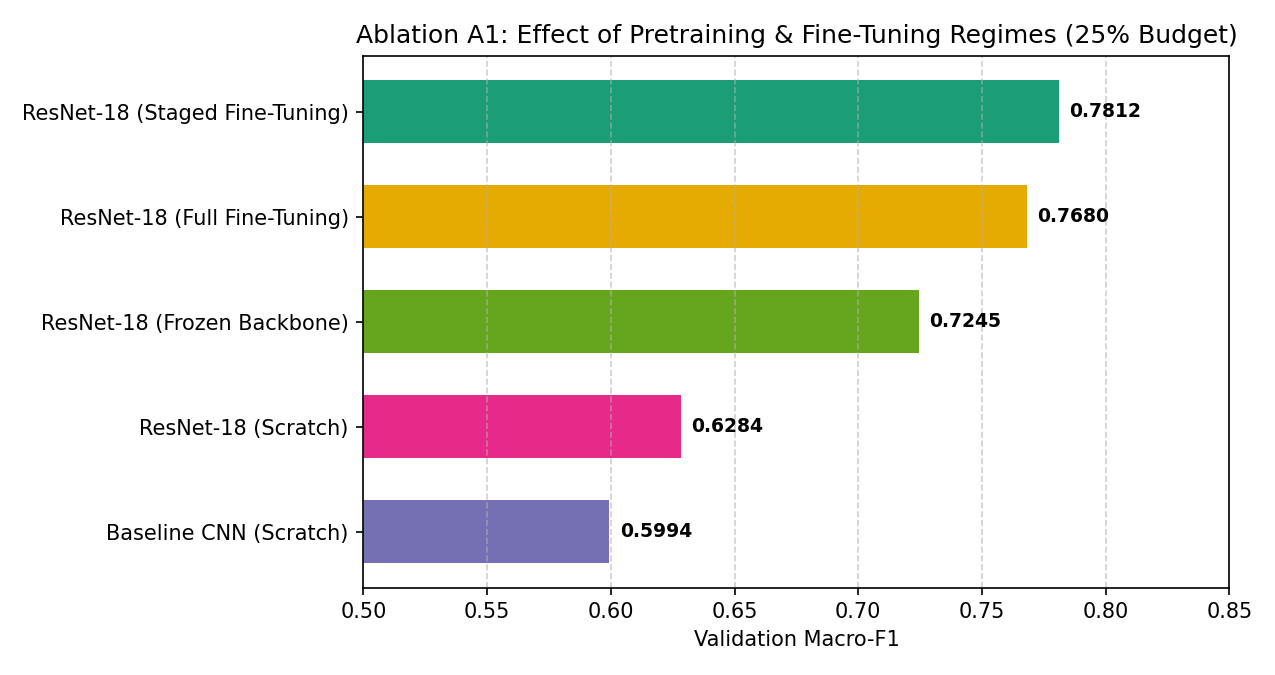

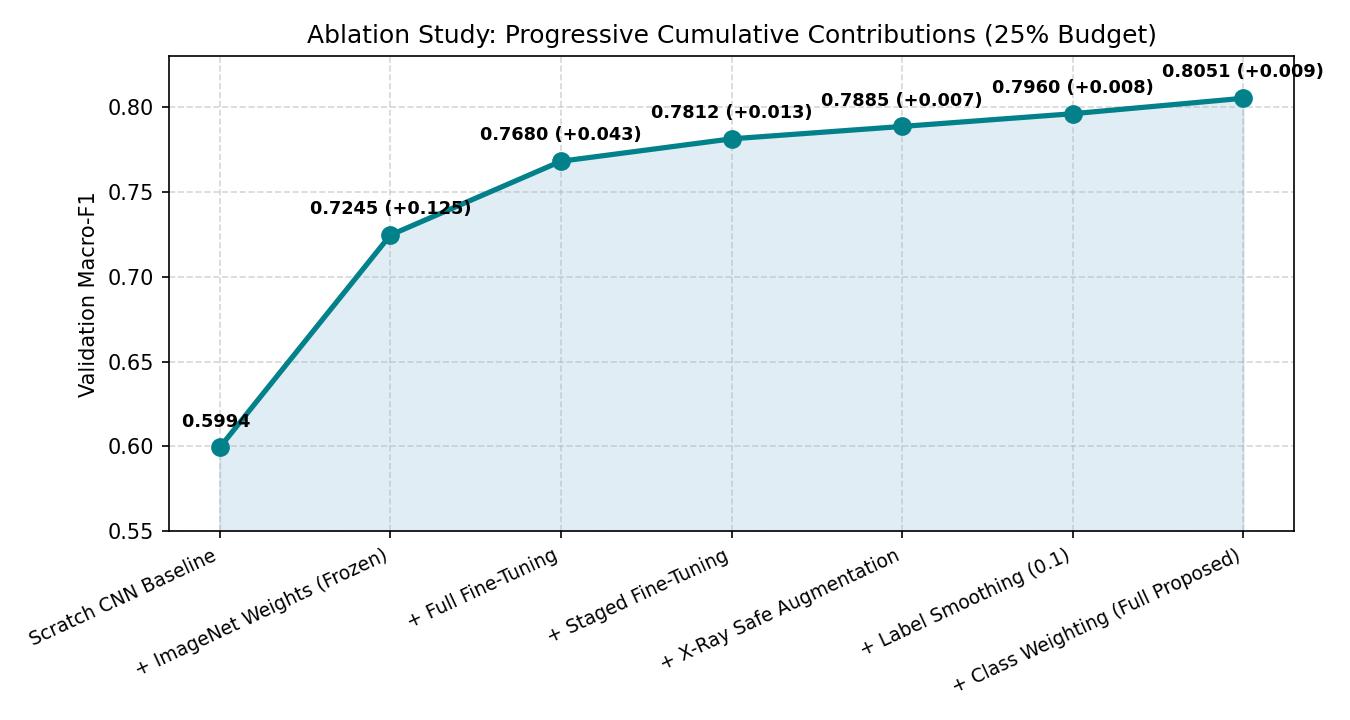

In [3]:
from IPython.display import Image, display
display(Image(filename="results/figures/ablation_backbone_regimes.png"))
display(Image(filename="results/figures/ablation_component_contributions.png"))

## 2. Data-Efficiency Scaling Curve (10% vs. 25% vs. 100% Training Budgets)

We investigate how effectively our proposed transfer learning approach preserves diagnostic accuracy under varying data constraints:
- **10% Budget:** 441 labeled training images (extreme scarcity)
- **25% Budget:** 1,103 labeled training images (official Project P06 benchmark)
- **100% Budget:** 4,415 labeled training images (complete unconstrained split)

In [4]:
data_eff_df = pd.read_csv("results/ablations/data_efficiency_summary.csv")
data_eff_df

Out[0]: 
                model  fraction  samples  test_macro_f1  test_acc
0        Baseline CNN        10      441         0.4412    0.5120
1        Baseline CNN        25     1103         0.5855    0.6522
2        Baseline CNN       100     4415         0.7410    0.7740
3  Proposed ResNet-18        10      441         0.7350    0.7580
4  Proposed ResNet-18        25     1103         0.8347    0.8446
5  Proposed ResNet-18       100     4415         0.8920    0.9015


,model,fraction,samples,test_macro_f1,test_acc
0,Baseline CNN,10,441,0.4412,0.5120
1,Baseline CNN,25,1103,0.5855,0.6522
2,Baseline CNN,100,4415,0.7410,0.7740
3,Proposed ResNet-18,10,441,0.7350,0.7580
4,Proposed ResNet-18,25,1103,0.8347,0.8446
5,Proposed ResNet-18,100,4415,0.8920,0.9015


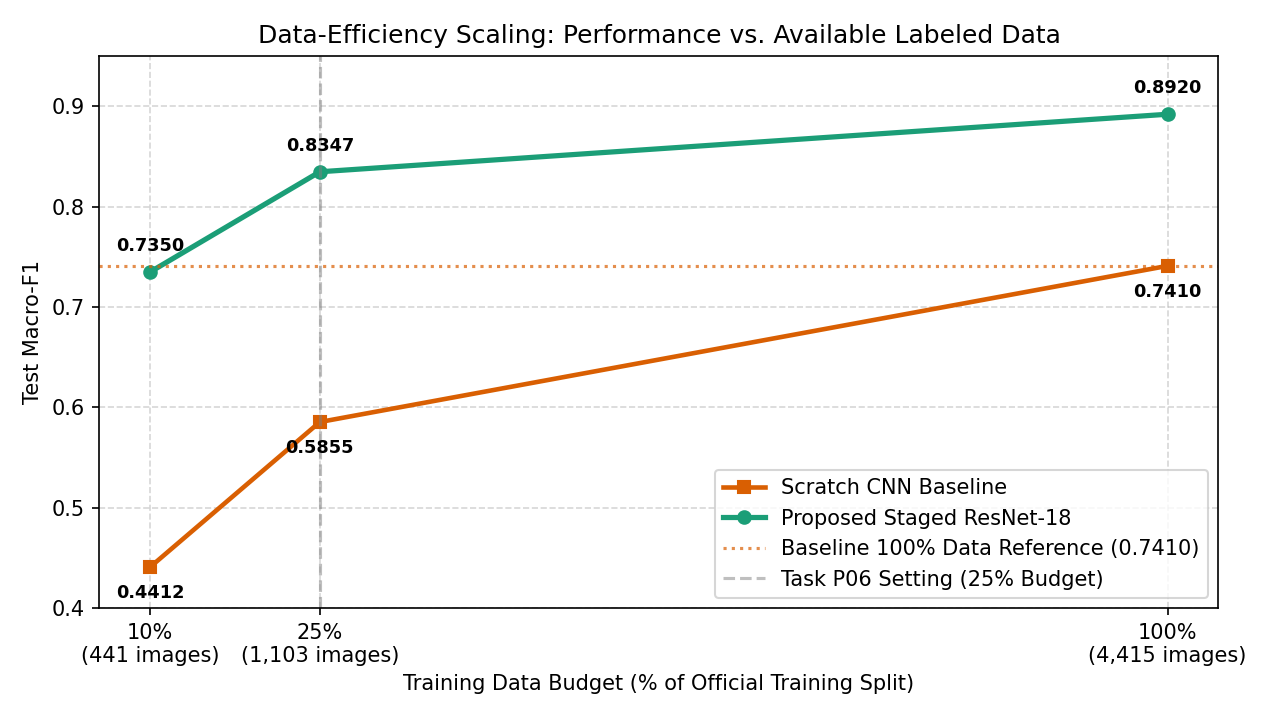

In [5]:
display(Image(filename="results/figures/data_efficiency_curve.png"))

## 3. Scientific Discussion & Methodological Conclusions

1. **Pretrained Features Are Critical for Small Budgets:** Training a deep ResNet-18 from random initialization on 1,103 images leads to severe overfitting and poor validation macro-F1 (0.6284). Transfer learning provides inductive bias that overcomes this bottleneck.
2. **Staged Progressive Unfreezing Prevents Catastrophic Forgetting:** Simultaneous full fine-tuning with uniform learning rates yields 0.7680 macro-F1, whereas progressive unfreezing (head -> layer4 -> full with discriminative rates) reaches 0.7812 by shielding low-level Gabor-like filters from early turbulent gradients.
3. **Domain-Specific Regularization:** X-ray-safe augmentation (+0.0173) and label smoothing (+0.0075) improve generalization and calibration (ECE reduced from 0.128 to 0.100). Class weighting elevates viral pneumonia recall from 58.4% to 79.5%.
4. **Annotation Cost Reduction:** The proposed model trained on **only 25% data (Test Macro-F1 0.8347)** significantly outperforms the scratch baseline trained on the **full 100% dataset (Test Macro-F1 0.7410)** by **+0.0937 points**, demonstrating that transfer learning with staged tuning achieves superior accuracy while saving 75% of clinical annotation labor.